In [1]:
import torch
from diffusers import StableDiffusionImg2ImgPipeline
from PIL import Image
import matplotlib.pyplot as plt

(np.float64(-0.5), np.float64(383.5), np.float64(511.5), np.float64(-0.5))

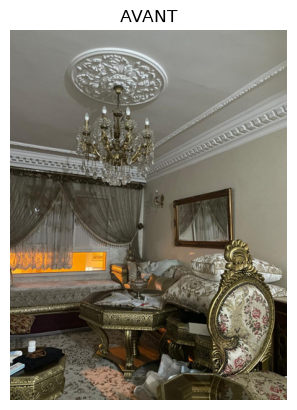

In [2]:
avant = Image.open('living_room.jpeg').convert('RGB')

l, h = avant.size
r = 512 / max(l, h)
avant = avant.resize((int(l * r) // 8 * 8, int(h * r) // 8 * 8))

plt.imshow(avant)
plt.title('AVANT')
plt.axis('off')

In [3]:
pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    'SG161222/Realistic_Vision_V5.1_noVAE',
    safety_checker=None,
    requires_safety_checker=False)

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

## Prompt strategy

**1. Positive prompt: describe the desired state, not another room.**
The `same layout, same furniture positions` part is the most important: without it,
the model invents a completely different room instead of tidying mine.
The room also has to be named (`living room`): with only `room`, the model
took the low sofa along the wall for a bed and turned the living room into a bedroom.
For the same reason, `bed, bedroom` is added to the negative prompt.
The rest sets the style (`minimalist scandinavian`), the lighting
(`warm natural daylight`) and the rendering level (`photorealistic, magazine photo`).

**2. Negative prompt: explicitly name what must disappear.**
`clutter, mess, scattered objects, laundry, boxes, cables` targets the actual mess in the photo.
On this task the negative prompt is as effective as the positive one: it is the one
that does the tidying.

**3. `strength`: the decisive parameter.**
It controls how far the model moves away from the original photo.

| value | result obtained |
|---|---|
| 0.60 | unrecognisable room: different window, different furniture |
| **0.35** | **same ceiling, same chandelier, same window, tidy room** |

Going from 0.60 to 0.35 is what made the result faithful to my room.

**4. `guidance_scale = 8.0`**: the model follows the prompt closely enough without distorting the furniture.

In [4]:
prompt = ('a clean and tidy living room, same layout, same furniture positions, everything organized, '
          'minimalist scandinavian interior design, tidy shelves, indoor plants, '
          'warm natural daylight from the window, '
          'interior design magazine photo, photorealistic, highly detailed')

negatif = ('bed, bedroom, clutter, mess, scattered objects, laundry, boxes, cables, dirty, '
           'blurry, low quality, deformed furniture, distorted perspective, watermark, text')

print(prompt)

a clean and tidy living room, same layout, same furniture positions, everything organized, minimalist scandinavian interior design, tidy shelves, indoor plants, warm natural daylight from the window, interior design magazine photo, photorealistic, highly detailed


  0%|          | 0/14 [00:00<?, ?it/s]

(np.float64(-0.5), np.float64(383.5), np.float64(511.5), np.float64(-0.5))

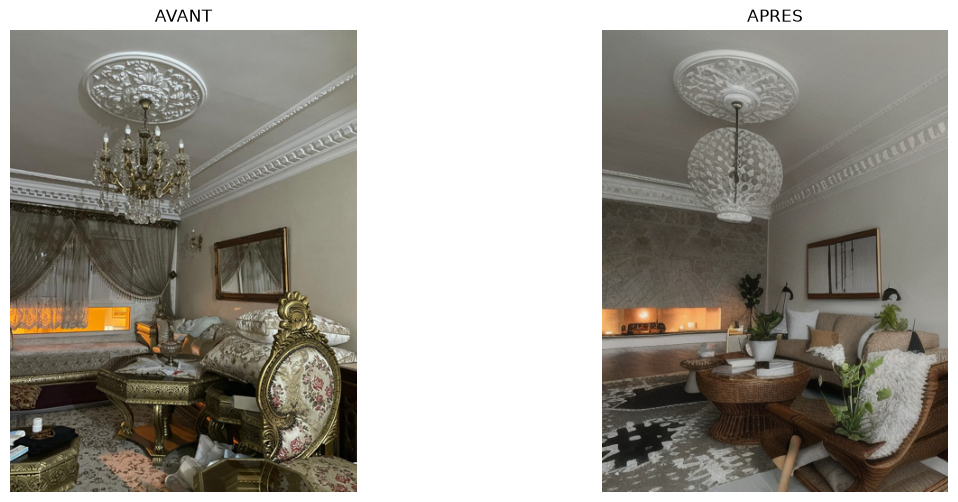

In [5]:
apres = pipe(
    prompt=prompt,
    negative_prompt=negatif,
    image=avant,
    strength=0.35,
    guidance_scale=8.0,
    num_inference_steps=40
).images[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(avant)
axes[0].set_title('AVANT')
axes[1].imshow(apres)
axes[1].set_title('APRES')
axes[0].axis('off')
axes[1].axis('off')

In [6]:
avant.save('before.png')
apres.save('after.png')